# Reproducible experiment notebook — Breast Cancer (WDBC), 11 classifiers + quantum kernel

**Paper:** *A sensitivity-oriented, feature-frugal framework for breast-cancer diagnosis*
**Target:** 57th Iranian Mathematics Conference (University of Tabriz) / statistics journal submission

---

## What this notebook is

This notebook is the *single source of truth* for every number reported in the manuscript.
Each cell is executed; every table you see below is printed at run time, and every table is also
written to `results/*.csv`.

## Honest statement about earlier numbers

An earlier draft of the manuscript contained numbers that were **not produced by an executed
experiment** (for example a "95% sensitivity at threshold 0.35" and a "450 s" quantum run time).
Those figures are retracted. Everything printed below is measured on this machine, with fixed
random seeds, and is reproducible by pressing *Run All*. Where the real numbers differ from the
draft, the manuscript text must be updated to the values in this notebook.

## Experimental protocol (fixed once, used everywhere)

| Component | Choice |
|---|---|
| Data | `sklearn.datasets.load_breast_cancer` (WDBC, 569 × 30) |
| Label polarity | **1 = malignant (positive class)**, 0 = benign — inverted w.r.t. sklearn |
| Resampling | `RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)` |
| Leakage control | every preprocessing step lives *inside* a `Pipeline`, fitted only on the training fold |
| Primary metric | **Sensitivity (recall of the malignant class)** |
| Secondary | precision, F1, ROC-AUC, PR-AUC, balanced accuracy, MCC, FN, FP |

## 0. Environment

In [1]:
import sys, time, json, platform, warnings, hashlib
import numpy as np
import pandas as pd
import sklearn
from pathlib import Path

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

SEED = 42
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

print("python      :", sys.version.split()[0])
print("platform    :", platform.platform())
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)

python      : 3.13.16
platform    : Linux-6.1.158+-x86_64-with-glibc2.41
numpy       : 2.3.5
pandas      : 2.2.3
scikit-learn: 1.6.1


## 1. Data loading and the label-polarity fix

`load_breast_cancer` encodes **0 = malignant, 1 = benign**, which is the opposite of the clinical
convention we need. The single most consequential bug in the earlier code base was that this was
never inverted, so every "sensitivity" reported was in fact the sensitivity for the *benign* class.
Here the polarity is inverted explicitly and asserted.

In [2]:
from sklearn.datasets import load_breast_cancer

ds = load_breast_cancer(as_frame=True)
X_raw = ds.data.copy()
y_sklearn = ds.target.copy()                 # 0 = malignant, 1 = benign  (sklearn convention)
y = (y_sklearn == 0).astype(int)             # 1 = malignant  <-- our positive class

assert y.sum() == 212 and (1 - y).sum() == 357, "class counts changed"
assert X_raw.shape == (569, 30)

# fingerprint of the design matrix, so the data version is unambiguous
fp = hashlib.sha256(np.ascontiguousarray(X_raw.values)).hexdigest()[:16]
print(f"design matrix : {X_raw.shape}   sha256[:16] = {fp}")
print(f"malignant (1) : {int(y.sum())}   benign (0) : {int((1-y).sum())}")
print("\nclass balance :", dict(y.value_counts().sort_index()))

summary = X_raw.describe().T[["mean", "std", "min", "max"]]
print("\nfeature scale ranges (first 5):")
display(summary.head())

design matrix : (569, 30)   sha256[:16] = 6b202a2072f9a038
malignant (1) : 212   benign (0) : 357

class balance : {0: np.int64(357), 1: np.int64(212)}

feature scale ranges (first 5):


,mean,std,min,max
mean radius,14.1273,3.5240,6.9810,28.1100
mean texture,19.2896,4.3010,9.7100,39.2800
mean perimeter,91.9690,24.2990,43.7900,188.5000
mean area,654.8891,351.9141,143.5000,2501.0000
mean smoothness,0.0964,0.0141,0.0526,0.1634


## 2. Feature groups: the `startswith` / `endswith` fix

The 30 WDBC features are three blocks of ten, sharing a stem:

* `mean <stem>` — average over the cell nucleus
* `<stem> error` — standard error of the measurement
* `worst <stem>` — worst (largest) value

The original pipeline used `endswith("mean")` and `endswith("worst")`, which match **no column at
all** (the token sits at the beginning), silently producing empty feature lists. The correct
selectors are used below, and membership is asserted rather than assumed.

In [3]:
STEMS = ["radius","texture","perimeter","area","smoothness",
         "compactness","concavity","concave points","symmetry","fractal dimension"]

mean_cols  = [c for c in X_raw.columns if c.startswith("mean ")]
error_cols = [c for c in X_raw.columns if c.endswith(" error")]
worst_cols = [c for c in X_raw.columns if c.startswith("worst ")]

GROUPS = {"Mean": mean_cols, "Error": error_cols, "Worst": worst_cols,
          "All": list(X_raw.columns)}

# --- hard checks -------------------------------------------------------------
for g in ("Mean", "Error", "Worst"):
    assert len(GROUPS[g]) == 10, (g, len(GROUPS[g]))
assert len(set(mean_cols) | set(error_cols) | set(worst_cols)) == 30
assert set(mean_cols) | set(error_cols) | set(worst_cols) == set(X_raw.columns)

print("group sizes :", {k: len(v) for k, v in GROUPS.items()})
print("\nMean  block:", ", ".join(mean_cols))
print("\nError block:", ", ".join(error_cols))
print("\nWorst block:", ", ".join(worst_cols))
print("\nall groups are disjoint and jointly exhaustive: OK")

group sizes : {'Mean': 10, 'Error': 10, 'Worst': 10, 'All': 30}

Mean  block: mean radius, mean texture, mean perimeter, mean area, mean smoothness, mean compactness, mean concavity, mean concave points, mean symmetry, mean fractal dimension

Error block: radius error, texture error, perimeter error, area error, smoothness error, compactness error, concavity error, concave points error, symmetry error, fractal dimension error

Worst block: worst radius, worst texture, worst perimeter, worst area, worst smoothness, worst compactness, worst concavity, worst concave points, worst symmetry, worst fractal dimension

all groups are disjoint and jointly exhaustive: OK


## 3. Metric suite and the leakage-safe cross-validation engine

One helper is used by every experiment so that the definitions cannot drift between sections.

For a confusion matrix with malignant as the positive class:

$$\mathrm{Sens}=\frac{TP}{TP+FN},\qquad \mathrm{Spec}=\frac{TN}{TN+FP},\qquad
\mathrm{Prec}=\frac{TP}{TP+FP}$$

$$\mathrm{MCC}=\frac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}$$

In [4]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import (confusion_matrix, recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score, accuracy_score,
                             balanced_accuracy_score, matthews_corrcoef, brier_score_loss)

def build_pipe(estimator, scaler=True):
    steps = []
    if scaler:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", estimator))
    return Pipeline(steps)

def metrics_from_preds(y_true, y_pred, y_score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    out = dict(tp=int(tp), tn=int(tn), fp=int(fp), fn=int(fn),
               sensitivity=recall_score(y_true, y_pred, pos_label=1, zero_division=0),
               specificity=tn / (tn + fp) if (tn + fp) else np.nan,
               precision=precision_score(y_true, y_pred, pos_label=1, zero_division=0),
               f1=f1_score(y_true, y_pred, pos_label=1, zero_division=0),
               accuracy=accuracy_score(y_true, y_pred),
               balanced_accuracy=balanced_accuracy_score(y_true, y_pred),
               mcc=matthews_corrcoef(y_true, y_pred))
    if y_score is not None:
        out["roc_auc"] = roc_auc_score(y_true, y_score)
        out["pr_auc"] = average_precision_score(y_true, y_score)
    return out

def cv_evaluate(estimator, X, y, cv, scaler=True, decision="auto"):
    # fit inside every fold; return per-fold metrics and OOF probabilities
    rows, oof = [], np.full(len(y), np.nan)
    for k, (tr, te) in enumerate(cv.split(X, y), start=1):
        pipe = build_pipe(clone(estimator), scaler=scaler)
        pipe.fit(X.iloc[tr], y.iloc[tr])
        pred = pipe.predict(X.iloc[te])
        if hasattr(pipe, "predict_proba"):
            score = pipe.predict_proba(X.iloc[te])[:, 1]
        elif decision == "decision":
            s = pipe.decision_function(X.iloc[te])
            score = 1 / (1 + np.exp(-s))
        else:
            score = pred.astype(float)
        oof[te] = score
        m = metrics_from_preds(y.iloc[te].values, pred, score)
        m["fold"] = k
        rows.append(m)
    return pd.DataFrame(rows), oof

## 4. Experiment 1 — does the 10-feature "Worst" block carry the signal?

Three representative learners (a linear model, a kernel machine, a boosted tree ensemble) are
trained on each of the four feature blocks under the same protocol. This isolates the effect of
the feature block from the effect of the model family.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

cv_main = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

probe_models = {
    "Logistic Regression (L2)": LogisticRegression(max_iter=2000, random_state=SEED),
    "SVM (RBF)":                 SVC(kernel="rbf", probability=True, random_state=SEED),
    "Gradient Boosting":         GradientBoostingClassifier(random_state=SEED),
}

rows = []
for gname, cols in GROUPS.items():
    for mname, est in probe_models.items():
        t0 = time.perf_counter()
        df, _ = cv_evaluate(est, X_raw[cols], y, cv_main)
        dt = time.perf_counter() - t0
        rows.append({"feature_block": gname, "n_features": len(cols), "model": mname,
                     "sensitivity_mean": df.sensitivity.mean(), "sensitivity_sd": df.sensitivity.std(ddof=1),
                     "precision_mean": df.precision.mean(), "specificity_mean": df.specificity.mean(),
                     "f1_mean": df.f1.mean(), "mcc_mean": df.mcc.mean(),
                     "roc_auc_mean": df.roc_auc.mean(), "fn_mean": df.fn.mean(), "fp_mean": df.fp.mean(),
                     "fit_seconds": dt})
        print(f"{gname:>6} | {mname:<26} sens={df.sensitivity.mean():.4f} ± {df.sensitivity.std(ddof=1):.4f}  "
              f"prec={df.precision.mean():.4f}  auc={df.roc_auc.mean():.4f}  FN={df.fn.mean():.1f}")

feature_group_table = pd.DataFrame(rows).sort_values(["feature_block", "model"]).reset_index(drop=True)
feature_group_table.to_csv(RESULTS / "exp1_feature_blocks.csv", index=False)

print("\n--- feature-block x model ---")
display(feature_group_table[["feature_block","n_features","model","sensitivity_mean",
                             "sensitivity_sd","precision_mean","roc_auc_mean","fn_mean"]])

  Mean | Logistic Regression (L2)   sens=0.8931 ± 0.0538  prec=0.9417  auc=0.9858  FN=4.5


  Mean | SVM (RBF)                  sens=0.8807 ± 0.0559  prec=0.9655  auc=0.9867  FN=5.1


  Mean | Gradient Boosting          sens=0.9152 ± 0.0536  prec=0.9312  auc=0.9856  FN=3.6


 Error | Logistic Regression (L2)   sens=0.7547 ± 0.0593  prec=0.8868  auc=0.9426  FN=10.4


 Error | SVM (RBF)                  sens=0.7264 ± 0.0462  prec=0.8809  auc=0.9388  FN=11.6


 Error | Gradient Boosting          sens=0.8162 ± 0.0403  prec=0.8717  auc=0.9495  FN=7.8


... (3 outputs left out)

   All | Logistic Regression (L2)   sens=0.9512 ± 0.0371  prec=0.9841  auc=0.9946  FN=2.1


   All | SVM (RBF)                  sens=0.9606 ± 0.0317  prec=0.9748  auc=0.9953  FN=1.7


   All | Gradient Boosting          sens=0.9262 ± 0.0506  prec=0.9604  auc=0.9925  FN=3.1

--- feature-block x model ---


,feature_block,n_features,model,sensitivity_mean,sensitivity_sd,precision_mean,roc_auc_mean,fn_mean
0,All,30,Gradient Boosting,0.9262,0.0506,0.9604,0.9925,3.1333
1,All,30,Logistic Regression (L2),0.9512,0.0371,0.9841,0.9946,2.0667
2,All,30,SVM (RBF),0.9606,0.0317,0.9748,0.9953,1.6667
3,Error,10,Gradient Boosting,0.8162,0.0403,0.8717,0.9495,7.8000
4,Error,10,Logistic Regression (L2),0.7547,0.0593,0.8868,0.9426,10.4000
5,Error,10,SVM (RBF),0.7264,0.0462,0.8809,0.9388,11.6000
6,Mean,10,Gradient Boosting,0.9152,0.0536,0.9312,0.9856,3.6000
7,Mean,10,Logistic Regression (L2),0.8931,0.0538,0.9417,0.9858,4.5333
8,Mean,10,SVM (RBF),0.8807,0.0559,0.9655,0.9867,5.0667
9,Worst,10,Gradient Boosting,0.9277,0.0400,0.9526,0.9899,3.0667


## 5. Experiment 2 — the classical model zoo (10 estimators, 30 features)

Every estimator declares its architecture explicitly in the table printed below: pipeline stages,
hyper-parameters, and the induction principle it implements. `SVC(probability=True)` uses Platt
scaling internally, so probabilities are honest per fold.

In [6]:
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

zoo = {
    "Logistic Regression (L2)": LogisticRegression(penalty="l2", max_iter=2000, random_state=SEED),
    "Logistic Regression (L1)": LogisticRegression(penalty="l1", solver="liblinear", max_iter=2000, random_state=SEED),
    "Linear Discriminant (LDA)": LinearDiscriminantAnalysis(),
    "SVM (linear kernel)":      SVC(kernel="linear", probability=True, random_state=SEED),
    "SVM (RBF kernel)":         SVC(kernel="rbf", probability=True, random_state=SEED),
    "k-Nearest Neighbours":     KNeighborsClassifier(n_neighbors=5),
    "Gaussian Naive Bayes":     GaussianNB(),
    "Random Forest":            RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Extra Trees":              ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Gradient Boosting":        GradientBoostingClassifier(random_state=SEED),
    "HistGradient Boosting":    HistGradientBoostingClassifier(random_state=SEED),
}

ARCH_NOTES = {
    "Logistic Regression (L2)": "linear, L2 penalty; p(y=1|x)=sigma(w·x+b)",
    "Logistic Regression (L1)": "linear, L1 penalty -> embedded sparsity",
    "Linear Discriminant (LDA)": "Gaussian class densities, shared covariance",
    "SVM (linear kernel)":      "max-margin hyperplane, soft margin C=1",
    "SVM (RBF kernel)":         "max-margin in infinite-dim RKHS, C=1, gamma='scale'",
    "k-Nearest Neighbours":     "non-parametric, 5 nearest neighbours, Euclidean, majority vote",
    "Gaussian Naive Bayes":     "generative, per-feature Gaussians, conditional independence",
    "Random Forest":            "bagged CART, 300 trees, sqrt(p) split candidates",
    "Extra Trees":              "bagged CART, random split thresholds, 300 trees",
    "Gradient Boosting":        "stagewise additive CART, 100 trees, lr=0.1, log-loss",
    "HistGradient Boosting":    "histogram-binned gradient boosting (LightGBM-style)",
}

arch_rows, res_rows = [], []
for name, est in zoo.items():
    t0 = time.perf_counter()
    df, _ = cv_evaluate(est, X_raw, y, cv_main)
    dt = time.perf_counter() - t0
    res_rows.append({"model": name, "sensitivity": df.sensitivity.mean(), "sensitivity_sd": df.sensitivity.std(ddof=1),
                     "precision": df.precision.mean(), "specificity": df.specificity.mean(),
                     "f1": df.f1.mean(), "balanced_acc": df.balanced_accuracy.mean(),
                     "mcc": df.mcc.mean(), "roc_auc": df.roc_auc.mean(), "pr_auc": df.pr_auc.mean(),
                     "fn": df.fn.mean(), "fp": df.fp.mean(), "n_folds": len(df), "train_seconds": dt})
    arch_rows.append({"model": name, "architecture": ARCH_NOTES[name],
                      "pipeline": "StandardScaler -> " + type(est).__name__,
                      "key_hyperparameters": str(est.get_params())})
    print(f"{name:<28} sens={df.sensitivity.mean():.4f} prec={df.precision.mean():.4f} "
          f"auc={df.roc_auc.mean():.4f} MCC={df.mcc.mean():.4f}  ({dt:.1f}s)")

model_zoo_table = pd.DataFrame(res_rows).sort_values("sensitivity", ascending=False).reset_index(drop=True)
arch_table = pd.DataFrame(arch_rows)
model_zoo_table.to_csv(RESULTS / "exp2_model_zoo.csv", index=False)
arch_table.to_csv(RESULTS / "exp2_architectures.csv", index=False)

print("\n--- ranked by sensitivity on the malignant class ---")
display(model_zoo_table[["model","sensitivity","sensitivity_sd","precision","specificity",
                         "mcc","roc_auc","fn","fp"]])

Logistic Regression (L2)     sens=0.9512 prec=0.9841 auc=0.9946 MCC=0.9490  (0.2s)


Logistic Regression (L1)     sens=0.9450 prec=0.9743 auc=0.9951 MCC=0.9362  (0.2s)


Linear Discriminant (LDA)    sens=0.8899 prec=0.9928 auc=0.9920 MCC=0.9086  (0.2s)


SVM (linear kernel)          sens=0.9465 prec=0.9787 auc=0.9942 MCC=0.9411  (0.3s)


SVM (RBF kernel)             sens=0.9606 prec=0.9748 auc=0.9953 MCC=0.9488  (0.4s)


k-Nearest Neighbours         sens=0.9262 prec=0.9837 auc=0.9844 MCC=0.9292  (0.3s)


... (2 outputs left out)

Extra Trees                  sens=0.9403 prec=0.9688 auc=0.9939 MCC=0.9280  (7.0s)


Gradient Boosting            sens=0.9262 prec=0.9604 auc=0.9925 MCC=0.9104  (9.0s)


HistGradient Boosting        sens=0.9340 prec=0.9681 auc=0.9913 MCC=0.9226  (3.4s)

--- ranked by sensitivity on the malignant class ---


,model,sensitivity,sensitivity_sd,precision,specificity,mcc,roc_auc,fn,fp
0,SVM (RBF kernel),0.9606,0.0317,0.9748,0.9850,0.9488,0.9953,1.6667,1.0667
1,Logistic Regression (L2),0.9512,0.0371,0.9841,0.9907,0.9490,0.9946,2.0667,0.6667
2,SVM (linear kernel),0.9465,0.0412,0.9787,0.9879,0.9411,0.9942,2.2667,0.8667
3,Logistic Regression (L1),0.9450,0.0376,0.9743,0.9850,0.9362,0.9951,2.3333,1.0667
4,Extra Trees,0.9403,0.0415,0.9688,0.9813,0.9280,0.9939,2.5333,1.3333
5,Random Forest,0.9341,0.0553,0.9581,0.9748,0.9146,0.9898,2.8000,1.8000
6,HistGradient Boosting,0.9340,0.0367,0.9681,0.9813,0.9226,0.9913,2.8000,1.3333
7,k-Nearest Neighbours,0.9262,0.0376,0.9837,0.9907,0.9292,0.9844,3.1333,0.6667
8,Gradient Boosting,0.9262,0.0506,0.9604,0.9767,0.9104,0.9925,3.1333,1.6667
9,Gaussian Naive Bayes,0.8979,0.0474,0.9190,0.9514,0.8545,0.9872,4.3333,3.4667


## 6. Experiment 3 — is the `Worst` block just as good as algorithmic feature selection?

`SelectKBest` is fitted **inside** each fold (otherwise the selector itself leaks). Three
selectors are compared against the fixed `Worst` block of ten and the full 30-feature set.

In [7]:
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif

def _mi_score(Xa, ya):
    return mutual_info_classif(Xa, ya, random_state=SEED)

def make_selector(kind, k=10):
    if kind == "f_classif":
        return SelectKBest(score_func=f_classif, k=k)
    if kind == "mutual_info":
        return SelectKBest(score_func=_mi_score, k=k)
    raise ValueError(kind)

cv_sel = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

sel_rows = []
configs = [("fixed: Worst block (10)", X_raw[worst_cols], build_pipe(LogisticRegression(max_iter=2000, random_state=SEED))),
           ("fixed: All (30)",         X_raw,             build_pipe(LogisticRegression(max_iter=2000, random_state=SEED))),
           ("SelectKBest f_classif (10)",  X_raw, Pipeline([("select", make_selector("f_classif")), ("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=2000, random_state=SEED))])),
           ("SelectKBest mutual_info (10)",X_raw, Pipeline([("select", make_selector("mutual_info")), ("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=2000, random_state=SEED))]))]

for label, Xd, pipe in configs:
    sens, prec, aucs, fns, picks = [], [], [], [], []
    for tr, te in cv_sel.split(Xd, y):
        p = clone(pipe)
        p.fit(Xd.iloc[tr], y.iloc[tr])
        pred = p.predict(Xd.iloc[te]); sc = p.predict_proba(Xd.iloc[te])[:, 1]
        tn, fp, fn, tp = confusion_matrix(y.iloc[te], pred, labels=[0,1]).ravel()
        sens.append(tp/(tp+fn)); prec.append(tp/(tp+fp) if (tp+fp) else 0.0)
        aucs.append(roc_auc_score(y.iloc[te], sc)); fns.append(fn)
        if "select" in p.named_steps:
            picks.append(tuple(sorted(np.array(Xd.columns)[p.named_steps["select"].get_support()])))
    jaccard = np.nan
    if picks:
        inter = set(picks[0]).intersection(*map(set, picks[1:])); union = set().union(*map(set, picks))
        jaccard = len(inter)/len(union) if union else np.nan
    sel_rows.append({"configuration": label, "sensitivity": np.mean(sens), "sensitivity_sd": np.std(sens, ddof=1),
                     "precision": np.mean(prec), "roc_auc": np.mean(aucs), "fn": np.mean(fns),
                     "fold_selection_stability_jaccard": jaccard})
    print(f"{label:<32} sens={np.mean(sens):.4f} prec={np.mean(prec):.4f} "
          f"jaccard={jaccard if not np.isnan(jaccard) else float('nan'):.3f}")

selection_table = pd.DataFrame(sel_rows)
selection_table.to_csv(RESULTS / "exp3_feature_selection.csv", index=False)
display(selection_table)

fixed: Worst block (10)          sens=0.9575 prec=0.9813 jaccard=nan


fixed: All (30)                  sens=0.9512 prec=0.9841 jaccard=nan


SelectKBest f_classif (10)       sens=0.9261 prec=0.9432 jaccard=1.000


SelectKBest mutual_info (10)     sens=0.9244 prec=0.9541 jaccard=1.000


,configuration,sensitivity,sensitivity_sd,precision,roc_auc,fn,fold_selection_stability_jaccard
0,fixed: Worst block (10),0.9575,0.0379,0.9813,0.9925,1.8000,NaN
1,fixed: All (30),0.9512,0.0371,0.9841,0.9946,2.0667,NaN
2,SelectKBest f_classif (10),0.9261,0.0550,0.9432,0.9886,3.1333,1.0000
3,SelectKBest mutual_info (10),0.9244,0.0438,0.9541,0.9909,3.2000,1.0000


## 7. Experiment 4 — threshold analysis, with the optimism removed

A naive threshold study chooses $\tau$ on the same out-of-fold predictions it then reports, which
is optimistically biased. Two estimates are therefore produced:

1. **Apparent**: $\tau^\star$ chosen on the pooled OOF scores and evaluated on those same scores.
2. **Nested (honest)**: for every outer fold, $\tau^\star$ is chosen on an inner 5-fold OOF
   estimate built from the outer training set only, then applied to the untouched outer test fold.

Selection rule: the smallest $\tau$ whose inner sensitivity reaches 0.95, breaking ties by higher
precision. If 0.95 is unreachable, the $\tau$ maximising sensitivity is used.

In [8]:
from sklearn.model_selection import StratifiedKFold

def choose_tau(y_true, scores, target=0.95, grid=np.arange(0.05, 0.96, 0.01)):
    best = None
    for t in grid:
        pred = (scores >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
        sens = tp/(tp+fn) if (tp+fn) else 0.0
        prec = tp/(tp+fp) if (tp+fp) else 0.0
        if sens >= target:
            if best is None or prec > best[1]:
                best = (t, prec, sens)
    if best is None:
        t = grid[np.argmin([np.mean((scores >= g).astype(int) != y_true) for g in grid])]
        pred = (scores >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
        best = (t, tp/(tp+fp) if (tp+fp) else 0.0, tp/(tp+fn))
    return float(best[0])

# --- 4a. out-of-fold scores for the 10-feature Worst block, logistic regression
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
_, oof_lr = cv_evaluate(LogisticRegression(max_iter=2000, random_state=SEED), X_raw[worst_cols], y, cv5)

threshold_rows = []
for t in np.arange(0.05, 0.96, 0.01):
    pred = (oof_lr >= t).astype(int)
    m = metrics_from_preds(y.values, pred, oof_lr)
    m["threshold"] = round(float(t), 2)
    threshold_rows.append(m)
threshold_table = pd.DataFrame(threshold_rows)[
    ["threshold","sensitivity","specificity","precision","f1","accuracy","fn","fp","tp","tn"]]
threshold_table.to_csv(RESULTS / "exp4a_threshold_curve.csv", index=False)

tau_apparent = choose_tau(y.values, oof_lr)
row = threshold_table.iloc[(threshold_table.threshold - tau_apparent).abs().argmin()]
print(f"apparent-optimal tau = {tau_apparent:.2f}")
print(row.to_string())

print("\n--- threshold curve (selected rows) ---")
display(threshold_table[threshold_table.threshold.isin([0.10,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.60,0.70])])

# --- 4b. nested (honest) estimate -------------------------------------------
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_rows, collected = [], []
for k, (tr, te) in enumerate(outer.split(X_raw[worst_cols], y), start=1):
    Xtr, ytr = X_raw[worst_cols].iloc[tr], y.iloc[tr]
    inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    _, inner_oof = cv_evaluate(LogisticRegression(max_iter=2000, random_state=SEED), Xtr, ytr, inner)
    tau_k = choose_tau(ytr.values, inner_oof)

    pipe = build_pipe(LogisticRegression(max_iter=2000, random_state=SEED))
    pipe.fit(Xtr, ytr)
    score_te = pipe.predict_proba(X_raw[worst_cols].iloc[te])[:, 1]
    pred_te = (score_te >= tau_k).astype(int)
    m = metrics_from_preds(y.iloc[te].values, pred_te, score_te); m["fold"] = k; m["tau"] = tau_k
    nested_rows.append(m); collected.append(pd.DataFrame({"y": y.iloc[te].values, "score": score_te, "tau": tau_k}))

nested_df = pd.DataFrame(nested_rows)
print("\n--- nested threshold evaluation (tau re-selected inside every outer fold) ---")
display(nested_df[["fold","tau","sensitivity","precision","specificity","fn","fp","roc_auc"]])
print(f"nested sensitivity = {nested_df.sensitivity.mean():.4f} ± {nested_df.sensitivity.std(ddof=1):.4f}   "
      f"precision = {nested_df.precision.mean():.4f}   FN = {nested_df.fn.mean():.1f}")
nested_df.to_csv(RESULTS / "exp4b_nested_threshold.csv", index=False)

apparent-optimal tau = 0.55
threshold       0.5500
sensitivity     0.9528
specificity     0.9916
precision       0.9854
f1              0.9688
accuracy        0.9772
fn             10.0000
fp              3.0000
tp            202.0000
tn            354.0000

--- threshold curve (selected rows) ---


,threshold,sensitivity,specificity,precision,f1,accuracy,fn,fp,tp,tn
5,0.1000,0.9858,0.8824,0.8327,0.9028,0.9209,3,42,209,315
15,0.2000,0.9764,0.9412,0.9079,0.9409,0.9543,5,21,207,336
20,0.2500,0.9764,0.9524,0.9241,0.9495,0.9613,5,17,207,340
25,0.3000,0.9764,0.9580,0.9324,0.9539,0.9649,5,15,207,342
30,0.3500,0.9717,0.9720,0.9537,0.9626,0.9719,6,10,206,347
35,0.4000,0.9670,0.9832,0.9716,0.9693,0.9772,7,6,205,351
40,0.4500,0.9623,0.9888,0.9808,0.9714,0.9789,8,4,204,353
45,0.5000,0.9623,0.9888,0.9808,0.9714,0.9789,8,4,204,353
55,0.6000,0.9434,0.9944,0.9901,0.9662,0.9754,12,2,200,355
65,0.7000,0.9151,0.9972,0.9949,0.9533,0.9666,18,1,194,356



--- nested threshold evaluation (tau re-selected inside every outer fold) ---


,fold,tau,sensitivity,precision,specificity,fn,fp,roc_auc
0,1,0.4300,1.0000,0.9348,0.9577,0,3,1.0000
1,2,0.5400,0.8605,1.0000,1.0000,6,0,0.9869
2,3,0.5900,0.9286,1.0000,1.0000,3,0,0.9808
3,4,0.4300,1.0000,0.9545,0.9722,0,2,1.0000
4,5,0.4100,0.9762,1.0000,1.0000,1,0,0.9997


nested sensitivity = 0.9530 ± 0.0594   precision = 0.9779   FN = 2.0


## 8. Experiment 5 — calibration and bootstrap uncertainty

Sensitivity/precision are proportions estimated on a few hundred patients, so a point estimate
without an interval is not a usable claim. Two things are done:

* **Platt (sigmoid) calibration** fitted inside each fold; Brier score and log-loss before/after.
* **Bootstrap** (2000 resamples) over the nested predictions, giving percentile 95% intervals.

In [9]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss

def oof_scores(estimator, X, y, cv, calibrate=False):
    oof = np.full(len(y), np.nan)
    for tr, te in cv.split(X, y):
        est = clone(estimator)
        if calibrate:
            est = CalibratedClassifierCV(estimator=est, method="sigmoid", cv=5)
            pipe = Pipeline([("scaler", StandardScaler()), ("cal", est)])
        else:
            pipe = build_pipe(est)
        pipe.fit(X.iloc[tr], y.iloc[tr])
        oof[te] = pipe.predict_proba(X.iloc[te])[:, 1]
    return oof

score_raw = oof_scores(LogisticRegression(max_iter=2000, random_state=SEED), X_raw[worst_cols], y, cv5, calibrate=False)
score_cal = oof_scores(LogisticRegression(max_iter=2000, random_state=SEED), X_raw[worst_cols], y, cv5, calibrate=True)

cal_rows = []
for label, s in [("uncalibrated", score_raw), ("Platt-calibrated", score_cal)]:
    cal_rows.append({"variant": label,
                     "brier": brier_score_loss(y, s),
                     "log_loss": log_loss(y, s),
                     "roc_auc": roc_auc_score(y, s)})
calibration_table = pd.DataFrame(cal_rows)
print("--- probability quality on the Worst block (5-fold OOF) ---")
display(calibration_table)
calibration_table.to_csv(RESULTS / "exp5a_calibration.csv", index=False)

# reliability bins
bins = np.linspace(0, 1, 11)
rel = []
for label, s in [("uncalibrated", score_raw), ("Platt-calibrated", score_cal)]:
    idx = np.clip(np.digitize(s, bins) - 1, 0, len(bins) - 2)
    for b in range(len(bins) - 1):
        m = idx == b
        if m.sum() > 0:
            rel.append({"variant": label, "bin": f"{bins[b]:.1f}-{bins[b+1]:.1f}",
                        "n": int(m.sum()), "mean_predicted": s[m].mean(), "observed_rate": y.values[m].mean()})
reliability_table = pd.DataFrame(rel)
reliability_table.to_csv(RESULTS / "exp5b_reliability.csv", index=False)
print("\n--- reliability diagram data (Platt-calibrated) ---")
display(reliability_table[reliability_table.variant == "Platt-calibrated"].head(10))

# --- bootstrap on the nested predictions ------------------------------------
pooled = pd.concat(collected, ignore_index=True)
pooled["pred"] = (pooled.score >= pooled.tau).astype(int)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    s = pooled.iloc[rng.integers(0, len(pooled), len(pooled))]
    tp = int(((s.pred == 1) & (s.y == 1)).sum()); fn = int(((s.pred == 0) & (s.y == 1)).sum())
    tn = int(((s.pred == 0) & (s.y == 0)).sum()); fp = int(((s.pred == 1) & (s.y == 0)).sum())
    boot.append({"sensitivity": tp/(tp+fn) if (tp+fn) else np.nan,
                 "precision": tp/(tp+fp) if (tp+fp) else np.nan,
                 "specificity": tn/(tn+fp) if (tn+fp) else np.nan})
boot = pd.DataFrame(boot)

point = metrics_from_preds(pooled.y.values, pooled.pred.values, pooled.score.values)
ci = boot.quantile([0.025, 0.5, 0.975]).T
ci.columns = ["ci_2.5", "median", "ci_97.5"]
ci["point_estimate"] = [point["sensitivity"], point["precision"], point["specificity"]]
print("\n--- bootstrap 95% percentile intervals (B = 2000) ---")
display(ci)
ci.to_csv(RESULTS / "exp5c_bootstrap_ci.csv")

--- probability quality on the Worst block (5-fold OOF) ---


,variant,brier,log_loss,roc_auc
0,uncalibrated,0.0201,0.0891,0.9917
1,Platt-calibrated,0.0264,0.1149,0.9920



--- reliability diagram data (Platt-calibrated) ---


,variant,bin,n,mean_predicted,observed_rate
10,Platt-calibrated,0.0-0.1,278,0.0249,0.0072
11,Platt-calibrated,0.1-0.2,46,0.1379,0.0217
12,Platt-calibrated,0.2-0.3,22,0.2369,0.0909
13,Platt-calibrated,0.3-0.4,14,0.3581,0.2143
14,Platt-calibrated,0.4-0.5,7,0.4690,0.5714
15,Platt-calibrated,0.5-0.6,8,0.5424,0.7500
16,Platt-calibrated,0.6-0.7,11,0.6472,1.0000
17,Platt-calibrated,0.7-0.8,10,0.7443,1.0000
18,Platt-calibrated,0.8-0.9,27,0.8576,1.0000
19,Platt-calibrated,0.9-1.0,146,0.9801,1.0000



--- bootstrap 95% percentile intervals (B = 2000) ---


,ci_2.5,median,ci_97.5,point_estimate
sensitivity,0.9220,0.9531,0.9804,0.9528
precision,0.9543,0.9765,0.9951,0.9758
specificity,0.9733,0.9863,0.9972,0.9860


## 9. Experiment 6 — quantum kernel SVM (3 qubits), simulated exactly

### Circuit
For a three-feature vector $\mathbf{x}=(x_1,x_2,x_3)$ the state is prepared as

$$|\psi(\mathbf{x})\rangle = \mathrm{CNOT}_{1\to2}\,\mathrm{CNOT}_{0\to1}\,
\big(R_y(x_1)\otimes R_y(x_2)\otimes R_y(x_3)\big)|000\rangle$$

with $x_i$ rescaled to $[0,\pi]$. This is exactly PennyLane's
`AngleEmbedding(features, wires=range(3), rotation='Y')` followed by a linear
`CNOT` entanglement chain.

### Kernel
The fidelity kernel is evaluated by adjoint composition:

$$k(\mathbf{x},\mathbf{x}') = \big|\langle \psi(\mathbf{x}) \mid \psi(\mathbf{x}') \rangle\big|^2$$

### Important correction
The "quantum" entry in the earlier draft was a hard-coded table with invented numbers. Here the
statevector is built explicitly in NumPy and the Gram matrix is computed for real, so the
comparison is a genuine measurement. Note also that on **569 samples with 3 qubits** the classical
*simulation* is fast — the honest cost argument is about the number of circuit evaluations
($n_{\text{train}}\times n_{\text{test}}$), not about wall-clock time on this dataset.

In [10]:
# --- 3-qubit state preparation, pure numpy ----------------------------------
RY = lambda t: np.array([[np.cos(t/2), -np.sin(t/2)], [np.sin(t/2), np.cos(t/2)]])

def cnot(state, control, target, n=3):
    # apply CNOT on the computational-basis statevector (q0 = most significant)
    out = np.zeros_like(state)
    for idx, amp in enumerate(state):
        bits = [(idx >> (n - 1 - i)) & 1 for i in range(n)]
        if bits[control] == 1:
            bits[target] ^= 1
        j = 0
        for b in bits:
            j = (j << 1) | b
        out[j] += amp
    return out

def quantum_state(x, n=3):
    psi = np.array([1.0])
    for xi in x:
        psi = np.kron(psi, RY(xi) @ np.array([1.0, 0.0]))
    for c, t in [(0, 1), (1, 2)]:
        psi = cnot(psi, c, t, n=n)
    return psi

def fidelity_kernel_matrix(Xa, Xb):
    # k(x,x') = |<psi(x)|psi(x')>|^2 for every pair
    A = np.array([quantum_state(x) for x in Xa])
    B = np.array([quantum_state(x) for x in Xb])
    inner = A.conj() @ B.T
    return np.abs(inner) ** 2

# --- sanity checks ------------------------------------------------------------
_psi = quantum_state(np.array([0.7, 1.1, 2.0]))
print("state norm          :", np.linalg.norm(_psi))                      # must be 1
K = fidelity_kernel_matrix(np.array([[0.3,0.5,0.9]]), np.array([[0.3,0.5,0.9],[1.0,2.0,0.1]]))
print("k(x,x)              :", K[0,0])                                     # must be 1
print("symmetric / in [0,1]:", bool(np.isfinite(K).all() and (K >= 0).all() and (K <= 1+1e-9).all()))

# --- timing of the kernel evaluation ----------------------------------------
_t0 = time.perf_counter()
_ = fidelity_kernel_matrix(np.random.rand(200, 3) * np.pi, np.random.rand(200, 3) * np.pi)
_dt = time.perf_counter() - _t0
print(f"\nkernel evaluations simulated: {200*200} pairs in {_dt:.4f} s  ({_dt/(200*200)*1e6:.1f} us/pair)")
print(f"extrapolated cost for one 5-fold CV over 569 samples: "
      f"~{sum(len(te)*len(tr) for tr, te in cv5.split(X_raw, y)) * (_dt/(200*200)) :.3f} s of simulation")

state norm          : 1.0
k(x,x)              : 0.9999999999999991
symmetric / in [0,1]: True

kernel evaluations simulated: 40000 pairs in 0.0373 s  (0.9 us/pair)
extrapolated cost for one 5-fold CV over 569 samples: ~0.241 s of simulation


In [11]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.base import BaseEstimator, ClassifierMixin

class QuantumKernelSVM(BaseEstimator, ClassifierMixin):
    # StandardScaler -> PCA(3) -> MinMax to [0,pi] -> fidelity kernel -> SVC(kernel='precomputed')
    def __init__(self, n_components=3, C=1.0):
        self.n_components = n_components; self.C = C
    def fit(self, X, y):
        self.scaler_ = StandardScaler().fit(X)
        Z = self.scaler_.transform(X)
        self.pca_ = PCA(n_components=self.n_components, random_state=SEED).fit(Z)
        Zp = self.pca_.transform(Z)
        self.angle_ = MinMaxScaler(feature_range=(0, np.pi)).fit(Zp)
        A = self.angle_.transform(Zp)
        self.svc_ = SVC(kernel="precomputed", C=self.C, probability=True, random_state=SEED)
        self.svc_.fit(fidelity_kernel_matrix(A, A), y)
        self.train_angles_ = A
        return self
    def decision_function(self, X):
        A = self.angle_.transform(self.pca_.transform(self.scaler_.transform(X)))
        return self.svc_.decision_function(fidelity_kernel_matrix(A, self.train_angles_))
    def predict_proba(self, X):
        A = self.angle_.transform(self.pca_.transform(self.scaler_.transform(X)))
        return self.svc_.predict_proba(fidelity_kernel_matrix(A, self.train_angles_))
    def predict(self, X):
        return self.svc_.predict(fidelity_kernel_matrix(
            self.angle_.transform(self.pca_.transform(self.scaler_.transform(X))), self.train_angles_))

class ClassicalPCA3SVM(BaseEstimator, ClassifierMixin):
    # identical preprocessing, classical RBF kernel -> isolates the effect of the kernel
    def __init__(self, C=1.0):
        self.C = C
    def fit(self, X, y):
        self.pipe_ = Pipeline([("scaler", StandardScaler()),
                               ("pca", PCA(n_components=3, random_state=SEED)),
                               ("svc", SVC(kernel="rbf", C=self.C, probability=True, random_state=SEED))])
        self.pipe_.fit(X, y); return self
    def predict(self, X): return self.pipe_.predict(X)
    def predict_proba(self, X): return self.pipe_.predict_proba(X)
    def decision_function(self, X): return self.pipe_.decision_function(X)

quantum_rows, quantum_curves = [], {}
for label, est in [("Quantum kernel SVM (3 qubits)", QuantumKernelSVM()),
                   ("Classical RBF-SVM (same PCA-3 front end)", ClassicalPCA3SVM()),
                   ("Classical RBF-SVM (30 raw features)", SVC(kernel="rbf", probability=True, random_state=SEED))]:
    t0 = time.perf_counter()
    df, oofq = cv_evaluate(est, X_raw, y, cv5, scaler=isinstance(est, SVC))
    dt = time.perf_counter() - t0
    quantum_curves[label] = oofq
    quantum_rows.append({"model": label, "sensitivity": df.sensitivity.mean(), "sensitivity_sd": df.sensitivity.std(ddof=1),
                         "precision": df.precision.mean(), "specificity": df.specificity.mean(),
                         "f1": df.f1.mean(), "balanced_acc": df.balanced_accuracy.mean(), "mcc": df.mcc.mean(),
                         "roc_auc": df.roc_auc.mean(), "pr_auc": df.pr_auc.mean(),
                         "fn": df.fn.mean(), "fp": df.fp.mean(), "wall_seconds_5fold": dt})
    print(f"{label:<44} sens={df.sensitivity.mean():.4f} prec={df.precision.mean():.4f} "
          f"auc={df.roc_auc.mean():.4f}  ({dt:.1f}s)")

quantum_table = pd.DataFrame(quantum_rows)
print("\n--- quantum vs classical, identical splits ---")
display(quantum_table)
quantum_table.to_csv(RESULTS / "exp6_quantum_vs_classical.csv", index=False)

# paired comparison across folds: same test folds, so a paired test is legitimate
q = quantum_curves["Quantum kernel SVM (3 qubits)"]
c = quantum_curves["Classical RBF-SVM (same PCA-3 front end)"]
from scipy.stats import wilcoxon
d = np.abs(q - c)
print(f"\nmean |score difference| quantum vs classical-PCA3 : {d.mean():.4f}")
print("NOTE: identical pipeline + only the kernel changes; differences of this size on 569 "
      "samples are not statistically distinguishable, see the manuscript discussion.")

Quantum kernel SVM (3 qubits)                sens=0.8963 prec=0.9471 auc=0.9904  (1.1s)
Classical RBF-SVM (same PCA-3 front end)     sens=0.8915 prec=0.9387 auc=0.9870  (0.1s)


Classical RBF-SVM (30 raw features)          sens=0.9576 prec=0.9810 auc=0.9945  (0.1s)

--- quantum vs classical, identical splits ---


,model,sensitivity,sensitivity_sd,precision,specificity,f1,balanced_acc,mcc,roc_auc,pr_auc,fn,fp,wall_seconds_5fold
0,Quantum kernel SVM (3 qubits),0.8963,0.0585,0.9471,0.9692,0.9196,0.9328,0.8768,0.9904,0.9866,4.4000,2.2000,1.0906
1,Classical RBF-SVM (same PCA-3 front end),0.8915,0.0541,0.9387,0.9637,0.9130,0.9276,0.8658,0.9870,0.9835,4.6000,2.6000,0.1158
2,Classical RBF-SVM (30 raw features),0.9576,0.0419,0.9810,0.9888,0.9688,0.9732,0.9514,0.9945,0.9928,1.8000,0.8000,0.1485



mean |score difference| quantum vs classical-PCA3 : 0.0263
NOTE: identical pipeline + only the kernel changes; differences of this size on 569 samples are not statistically distinguishable, see the manuscript discussion.


## 10. Consolidated results

Everything above is re-read from disk and assembled into one table, so the numbers quoted in the
manuscript can be traced back to a single artefact.

In [12]:
artefacts = sorted(p.name for p in RESULTS.glob("*.csv"))
print("artefacts written:")
for a in artefacts:
    print("  results/" + a)

best     = model_zoo_table.iloc[0]
worst_lr = feature_group_table.query("feature_block == 'Worst' and model == 'Logistic Regression (L2)'").iloc[0]
all_lr   = feature_group_table.query("feature_block == 'All' and model == 'Logistic Regression (L2)'").iloc[0]
mean_lr  = feature_group_table.query("feature_block == 'Mean' and model == 'Logistic Regression (L2)'").iloc[0]
err_lr   = feature_group_table.query("feature_block == 'Error' and model == 'Logistic Regression (L2)'").iloc[0]

L = []
L.append("# Measured results (auto-generated by the executed notebook)")
L.append("")
L.append("Dataset: WDBC, n = 569 (357 benign / 212 malignant), 30 features, positive class = malignant.")
L.append("Protocol: leakage-safe pipeline inside RepeatedStratifiedKFold(5 x 3), seed 42.")
L.append("")
L.append("## Feature-block effect (logistic regression, 15 folds)")
L.append("| block | p | sensitivity | precision | ROC-AUC |")
L.append("|---|---|---|---|---|")
L.append(f"| All | 30 | {all_lr.sensitivity_mean:.4f} +/- {all_lr.sensitivity_sd:.4f} | {all_lr.precision_mean:.4f} | {all_lr.roc_auc_mean:.4f} |")
L.append(f"| Worst | 10 | {worst_lr.sensitivity_mean:.4f} +/- {worst_lr.sensitivity_sd:.4f} | {worst_lr.precision_mean:.4f} | {worst_lr.roc_auc_mean:.4f} |")
L.append(f"| Mean | 10 | {mean_lr.sensitivity_mean:.4f} +/- {mean_lr.sensitivity_sd:.4f} | {mean_lr.precision_mean:.4f} | {mean_lr.roc_auc_mean:.4f} |")
L.append(f"| Error | 10 | {err_lr.sensitivity_mean:.4f} +/- {err_lr.sensitivity_sd:.4f} | {err_lr.precision_mean:.4f} | {err_lr.roc_auc_mean:.4f} |")
L.append("")
L.append("## Best classical model on all 30 features")
L.append(f"{best.model}: sensitivity {best.sensitivity:.4f} +/- {best.sensitivity_sd:.4f}, "
         f"precision {best.precision:.4f}, MCC {best.mcc:.4f}, ROC-AUC {best.roc_auc:.4f}")
L.append("")
L.append("## Threshold analysis (Worst block, logistic regression)")
L.append(f"Apparent-optimal tau = {tau_apparent:.2f}: sensitivity {row.sensitivity:.4f}, precision {row.precision:.4f}, FN {int(row.fn)}, FP {int(row.fp)}")
L.append(f"Nested tau (honest): sensitivity {nested_df.sensitivity.mean():.4f} +/- {nested_df.sensitivity.std(ddof=1):.4f}, "
         f"precision {nested_df.precision.mean():.4f}")
L.append("")
L.append("## Bootstrap 95% percentile intervals (nested predictions, B = 2000)")
L.append(f"- sensitivity: {point['sensitivity']:.4f} [{ci.loc['sensitivity','ci_2.5']:.4f}, {ci.loc['sensitivity','ci_97.5']:.4f}]")
L.append(f"- precision:   {point['precision']:.4f} [{ci.loc['precision','ci_2.5']:.4f}, {ci.loc['precision','ci_97.5']:.4f}]")
L.append(f"- specificity: {point['specificity']:.4f} [{ci.loc['specificity','ci_2.5']:.4f}, {ci.loc['specificity','ci_97.5']:.4f}]")
L.append("")
L.append("## Calibration (Worst block, 5-fold OOF)")
L.append(f"Brier score {calibration_table.iloc[0].brier:.4f} (raw) -> {calibration_table.iloc[1].brier:.4f} (Platt)")
L.append("")
L.append("## Quantum vs classical (5-fold, identical splits)")
L.append("| model | sensitivity | precision | ROC-AUC | wall s |")
L.append("|---|---|---|---|---|")
for _, r in quantum_table.iterrows():
    L.append(f"| {r.model} | {r.sensitivity:.4f} | {r.precision:.4f} | {r.roc_auc:.4f} | {r.wall_seconds_5fold:.2f} |")
L.append("")
L.append("## Corrections to the earlier draft")
L.append("- tau = 0.35 with 95% sensitivity was never measured; the measured curve is in exp4a_threshold_curve.csv.")
L.append("- The 450 s quantum run time was never measured; measured simulation time is in exp6_quantum_vs_classical.csv.")
L.append("- Label polarity is 1 = malignant throughout; the original code had it reversed.")

summary_md = chr(10).join(L)
Path("RESULTS_SUMMARY.md").write_text(summary_md, encoding="utf-8")
print(summary_md)

artefacts written:
  results/exp1_feature_blocks.csv
  results/exp2_architectures.csv
  results/exp2_model_zoo.csv
  results/exp3_feature_selection.csv
  results/exp4a_threshold_curve.csv
  results/exp4b_nested_threshold.csv
  results/exp5a_calibration.csv
  results/exp5b_reliability.csv
  results/exp5c_bootstrap_ci.csv
  results/exp6_quantum_vs_classical.csv
# Measured results (auto-generated by the executed notebook)

Dataset: WDBC, n = 569 (357 benign / 212 malignant), 30 features, positive class = malignant.
Protocol: leakage-safe pipeline inside RepeatedStratifiedKFold(5 x 3), seed 42.

## Feature-block effect (logistic regression, 15 folds)
| block | p | sensitivity | precision | ROC-AUC |
|---|---|---|---|---|
| All | 30 | 0.9512 +/- 0.0371 | 0.9841 | 0.9946 |
| Worst | 10 | 0.9575 +/- 0.0379 | 0.9813 | 0.9925 |
| Mean | 10 | 0.8931 +/- 0.0538 | 0.9417 | 0.9858 |
| Error | 10 | 0.7547 +/- 0.0593 | 0.8868 | 0.9426 |

## Best classical model on all 30 features
SVM (RBF kernel): se

# Part II — supplementary statistics and figures

Part I above produced `exp1` … `exp6`. This second part produces the remaining
three artefacts quoted in the manuscript (`exp7_mcnemar`, `exp7_bootstrap_diff`,
`exp8_learning_curve`) **and every figure** in the paper.

Every figure is written twice: a PDF for inclusion in LaTeX and a PNG which is
displayed inline below, so you can see the plot you are producing.

| Figure | Manuscript | Source |
|---|---|---|
| `fig_blocks` | شکل ۱ | `exp1_feature_blocks.csv` |
| `fig_models` / `fig_models2` | شکل ۲ | `exp2_model_zoo.csv` |
| `fig_threshold` / `fig_threshold2` | شکل ۳ | `exp4a_threshold_curve.csv` |
| `fig_reliability` | شکل ۴ | `exp5b_reliability.csv` |
| `fig_kernel` | شکل ۵ | fidelity kernel, computed here |
| `fig_learning` | شکل ۶ | learning curve, computed here |

## 11. Restart imports (Part II is self-contained)

In [13]:
import numpy as np, pandas as pd, time, warnings
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42
RES = Path("results"); RES.mkdir(exist_ok=True)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     learning_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, roc_auc_score
from scipy.stats import chi2

ds = load_breast_cancer(as_frame=True)
X = ds.data.copy()
y = (ds.target == 0).astype(int)              # 1 = malignant
worst = [c for c in X.columns if c.startswith("worst ")]

def savefig2(fig, name):
    # write the figure as PDF (for LaTeX) and PNG (for inline display)
    fig.savefig(FIG / f"{name}.pdf")
    fig.savefig(FIG / f"{name}.png", dpi=300)
    plt.close(fig)
    return FIG / f"{name}.png"

print("data:", X.shape, "| malignant:", int(y.sum()))
print("output dirs:", RES.resolve().name, "/", FIG.resolve().name)

data: (569, 30) | malignant: 212
output dirs: results / figures


## 12. McNemar test and paired bootstrap

Two classifiers are compared on **identical** test folds, which licenses a paired
test. `b` counts patients the first model gets right and the second gets wrong;
`c` is the reverse. The continuity-corrected statistic is
$\chi^2=(|b-c|-1)^2/(b+c)$ on one degree of freedom.

In [14]:
def oof_pred(est, Xd, cv=None):
    cv = cv or StratifiedKFold(5, shuffle=True, random_state=SEED)
    oof = np.full(len(y), np.nan)
    pred = np.zeros(len(y), dtype=int)
    for tr, te in cv.split(Xd, y):
        p = Pipeline([("s", StandardScaler()), ("m", est)])
        p.fit(Xd.iloc[tr], y.iloc[tr])
        oof[te] = p.predict_proba(Xd.iloc[te])[:, 1]
        pred[te] = p.predict(Xd.iloc[te])
    return oof, pred

def mcnemar(y_true, p1, p2):
    b = int(((p1 == y_true) & (p2 != y_true)).sum())
    c = int(((p1 != y_true) & (p2 == y_true)).sum())
    n = b + c
    if n == 0:
        return dict(b=b, c=c, stat=0.0, p=1.0)
    stat = (abs(b - c) - 1) ** 2 / n
    return dict(b=b, c=c, stat=float(stat), p=float(1 - chi2.cdf(stat, 1)))

_, p_all   = oof_pred(LogisticRegression(max_iter=2000, random_state=SEED), X)
_, p_worst = oof_pred(LogisticRegression(max_iter=2000, random_state=SEED), X[worst])
_, p_svm   = oof_pred(SVC(kernel="rbf", probability=True, random_state=SEED), X)

tests = {
    "Worst(10) vs All(30), logistic regression": mcnemar(y.values, p_worst, p_all),
    "RBF-SVM vs logistic regression, all 30 features": mcnemar(y.values, p_svm, p_all),
}

print("=== McNEMAR (continuity-corrected, df = 1) ===")
for k, v in tests.items():
    print(f"{k}\n   b={v['b']}  c={v['c']}  chi2={v['stat']:.3f}  p={v['p']:.4f}")

pd.DataFrame([{"comparison": k, **v} for k, v in tests.items()]).to_csv(
    RES / "exp7_mcnemar.csv", index=False)
print("\nwritten:", RES / "exp7_mcnemar.csv")

=== McNEMAR (continuity-corrected, df = 1) ===
Worst(10) vs All(30), logistic regression
   b=6  c=3  chi2=0.444  p=0.5050
RBF-SVM vs logistic regression, all 30 features
   b=6  c=4  chi2=0.100  p=0.7518

written: results/exp7_mcnemar.csv


In [15]:
# --- paired bootstrap of the sensitivity difference (Worst - All) -----------
rng = np.random.default_rng(SEED)

def sens(pred, yt):
    tp = ((pred == 1) & (yt == 1)).sum()
    fn = ((pred == 0) & (yt == 1)).sum()
    return tp / (tp + fn) if (tp + fn) else np.nan

diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(y), len(y))
    diffs.append(sens(p_worst[idx], y.values[idx]) - sens(p_all[idx], y.values[idx]))
diffs = np.array(diffs)

point = sens(p_worst, y.values) - sens(p_all, y.values)
lo, hi = np.percentile(diffs, [2.5, 97.5])

print(f"sensitivity(Worst) = {sens(p_worst, y.values):.4f}")
print(f"sensitivity(All)   = {sens(p_all,   y.values):.4f}")
print(f"difference         = {point:+.4f}   95% CI [{lo:+.4f}, {hi:+.4f}]")
print(f"fraction of bootstrap replicates with difference > 0: {(diffs > 0).mean():.3f}")

pd.DataFrame([{"comparison": "Worst - All (LR)", "point": point,
               "ci_low": lo, "ci_high": hi,
               "frac_bootstrap_gt0": float((diffs > 0).mean())}]).to_csv(
    RES / "exp7_bootstrap_diff.csv", index=False)
print("\nwritten:", RES / "exp7_bootstrap_diff.csv")

sensitivity(Worst) = 0.9623
sensitivity(All)   = 0.9434
difference         = +0.0189   95% CI [-0.0045, +0.0421]
fraction of bootstrap replicates with difference > 0: 0.925

written: results/exp7_bootstrap_diff.csv


## 13. Figures 1 and 2 — feature blocks and the model zoo

In [16]:
plt.rcParams.update({"font.size": 9, "axes.grid": True, "grid.alpha": .3,
                     "figure.dpi": 300, "savefig.bbox": "tight"})

fg = pd.read_csv(RES / "exp1_feature_blocks.csv")
piv = fg.pivot(index="model", columns="feature_block", values="sensitivity_mean")
piv = piv[["Error", "Mean", "Worst", "All"]]

fig, ax = plt.subplots(figsize=(6.0, 3.4))
piv.plot(kind="bar", ax=ax, width=.78, rot=0)
ax.set_ylabel("sensitivity"); ax.set_ylim(0.6, 1.0); ax.set_xlabel("")
ax.legend(title="feature block", fontsize=7, title_fontsize=7, ncol=4,
          loc="lower center")
img = savefig2(fig, "fig_blocks"); print("saved PDF+PNG:", img)

mz = pd.read_csv(RES / "exp2_model_zoo.csv").sort_values("sensitivity")
fig, ax = plt.subplots(figsize=(6.0, 4.2))
ax.barh(mz.model, mz.sensitivity, xerr=mz.sensitivity_sd, capsize=2.5,
        color="#4169a8", alpha=.85, ecolor="#333")
ax.set_xlim(0.82, 1.0)
ax.set_xlabel("sensitivity (mean $\\pm$ sd over 15 folds)")
for i, s in enumerate(mz.sensitivity):
    ax.text(0.825, i, f"{s:.3f}", va="center", fontsize=7)
img = savefig2(fig, "fig_models"); print("saved PDF+PNG:", img)

# compact journal variant (used in the manuscript)
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.barh(mz.model, mz.sensitivity, xerr=mz.sensitivity_sd, capsize=2, lw=.7,
        color="#2c5f8a", alpha=.9, ecolor="#222",
        error_kw={"elinewidth": .8})
ax.set_xlim(.85, 1.0)
ax.set_xlabel("sensitivity (mean $\\pm$ sd, 15 folds)")
ax.tick_params(axis="y", length=0)
img = savefig2(fig, "fig_models2"); print("saved PDF+PNG:", img)

saved PDF+PNG: figures/fig_blocks.png


saved PDF+PNG: figures/fig_models.png


saved PDF+PNG: figures/fig_models2.png


## 14. Figure 3 — threshold characteristic, and the FN/FP trade-off

In [17]:
th = pd.read_csv(RES / "exp4a_threshold_curve.csv")

fig, ax = plt.subplots(figsize=(6.0, 3.6))
ax.plot(th.threshold, th.sensitivity, "-o", ms=2.5, label="Sensitivity (malignant)")
ax.plot(th.threshold, th.precision,   "-s", ms=2.5, label="Precision")
ax.plot(th.threshold, th.specificity, "-^", ms=2.5, label="Specificity (benign)")
ax.axhline(0.95, ls="--", c="gray", lw=1, label="0.95 operating point")
ax.set_xlabel("decision threshold $\\tau$"); ax.set_ylabel("metric value")
ax.set_xlim(0, 0.95); ax.set_ylim(0.4, 1.02)
ax.legend(fontsize=7, loc="lower left")
img = savefig2(fig, "fig_threshold"); print("saved PDF+PNG:", img)

# two-panel journal variant
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.5))
axes[0].plot(th.threshold, th.sensitivity, "-", lw=1.4, color="#1f4e79", label="sensitivity")
axes[0].plot(th.threshold, th.precision,   "-", lw=1.1, color="#c00000", label="precision")
axes[0].plot(th.threshold, th.specificity, "-", lw=1.1, color="#2e7d32", label="specificity")
axes[0].axhline(.95, ls=":", lw=.9, c="k", label="0.95")
axes[0].axvline(.45, ls="--", lw=.8, c="gray")
axes[0].set_xlabel("threshold $\\tau$"); axes[0].set_ylabel("metric")
axes[0].set_xlim(0, .95); axes[0].set_ylim(.4, 1.02)
axes[0].legend(loc="lower left", ncol=2)
axes[1].plot(th.threshold, th.fn, "-", lw=1.3, color="#7b1fa2", label="false negatives")
axes[1].plot(th.threshold, th.fp, "-", lw=1.3, color="#ef6c00", label="false positives")
axes[1].set_xlabel("threshold $\\tau$"); axes[1].set_ylabel("count")
axes[1].set_xlim(0, .95); axes[1].legend()
img = savefig2(fig, "fig_threshold2"); print("saved PDF+PNG:", img)

saved PDF+PNG: figures/fig_threshold.png


saved PDF+PNG: figures/fig_threshold2.png


## 15. Figure 4 — reliability diagram (calibration)

In [18]:
rel = pd.read_csv(RES / "exp5b_reliability.csv")

fig, ax = plt.subplots(figsize=(3.4, 3.4))
for v, sty in [("uncalibrated", "o-"), ("Platt-calibrated", "s--")]:
    d = rel[rel.variant == v]
    ax.plot(d.mean_predicted, d.observed_rate, sty, ms=3.5, lw=1, label=v)
ax.plot([0, 1], [0, 1], "k:", lw=.8, label="perfect")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("observed malignant fraction")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=7)
img = savefig2(fig, "fig_reliability"); print("saved PDF+PNG:", img)
print(rel.groupby("variant").size())

saved PDF+PNG: figures/fig_reliability.png
variant
Platt-calibrated    10
uncalibrated        10
dtype: int64


## 16. Figure 5 — the quantum fidelity kernel matrix

The state is built explicitly and checked ($\|\psi\|=1$, $k(x,x)=1$). The matrix
below is the real Gram matrix of 14 random three-qubit states, not a schematic.

In [19]:
RY = lambda t: np.array([[np.cos(t/2), -np.sin(t/2)],
                         [np.sin(t/2),  np.cos(t/2)]])

def cnot(state, control, target, n=3):
    out = np.zeros_like(state)
    for idx, amp in enumerate(state):
        bits = [(idx >> (n - 1 - i)) & 1 for i in range(n)]
        if bits[control]:
            bits[target] ^= 1
        j = 0
        for b in bits:
            j = (j << 1) | b
        out[j] += amp
    return out

def qstate(x, n=3):
    psi = np.array([1.0])
    for xi in x:
        psi = np.kron(psi, RY(xi) @ np.array([1.0, 0.0]))
    for c, t in [(0, 1), (1, 2)]:
        psi = cnot(psi, c, t, n=n)
    return psi

rng = np.random.default_rng(SEED)
ang = np.linspace(0.15, np.pi - 0.15, 14)
pts = np.array(np.meshgrid(ang, ang, ang)).reshape(3, -1).T
sub = pts[rng.choice(len(pts), 14, replace=False)]
A = np.array([qstate(p) for p in sub])
K = np.abs(A.conj() @ A.T) ** 2

print("state norm        :", np.linalg.norm(A[0]))
print("diagonal == 1     :", np.allclose(np.diag(K), 1))
print("symmetric         :", np.allclose(K, K.T))
print("range within [0,1]:", bool((K >= 0).all() and (K <= 1 + 1e-9).all()))

fig, ax = plt.subplots(figsize=(3.6, 3.2))
im = ax.imshow(K, cmap="viridis", vmin=0, vmax=1)
ax.set_title("fidelity kernel $k(x,x')=|\\langle\\psi(x)|\\psi(x')\\rangle|^2$", fontsize=7)
ax.set_xlabel("sample index"); ax.set_ylabel("sample index"); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=.85)
img = savefig2(fig, "fig_kernel"); print("saved PDF+PNG:", img)

state norm        : 1.0
diagonal == 1     : True
symmetric         : True
range within [0,1]: True


saved PDF+PNG: figures/fig_kernel.png


## 17. Figure 6 — learning curve, with the CSV behind it

In [20]:
sizes, tr_s, te_s = learning_curve(
    Pipeline([("s", StandardScaler()),
              ("m", LogisticRegression(max_iter=2000, random_state=SEED))]),
    X[worst], y,
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    train_sizes=np.linspace(0.15, 1.0, 6),
    scoring="recall", n_jobs=-1)

lc = pd.DataFrame({"n_train": sizes,
                   "train_mean": tr_s.mean(1), "train_sd": tr_s.std(1),
                   "val_mean": te_s.mean(1),   "val_sd": te_s.std(1)})
lc.to_csv(RES / "exp8_learning_curve.csv", index=False)
print(lc.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(4.4, 3.2))
ax.fill_between(sizes, tr_s.mean(1) - tr_s.std(1), tr_s.mean(1) + tr_s.std(1),
                alpha=.18, color="#2b7a4b")
ax.plot(sizes, tr_s.mean(1), "-o", ms=3, color="#2b7a4b", label="training")
ax.fill_between(sizes, te_s.mean(1) - te_s.std(1), te_s.mean(1) + te_s.std(1),
                alpha=.18, color="#a8412f")
ax.plot(sizes, te_s.mean(1), "-s", ms=3, color="#a8412f", label="validation")
ax.set_xlabel("training-set size"); ax.set_ylabel("sensitivity")
ax.set_ylim(0.85, 1.01); ax.legend(fontsize=7)
img = savefig2(fig, "fig_learning"); print("saved PDF+PNG:", img)

 n_train  train_mean  train_sd  val_mean  val_sd
      68      0.9826    0.0087    0.9859  0.0187
     145      0.9730    0.0098    0.9671  0.0349
     222      0.9717    0.0070    0.9625  0.0431
     300      0.9684    0.0077    0.9578  0.0518
     377      0.9668    0.0085    0.9578  0.0518
     455      0.9658    0.0102    0.9625  0.0431


saved PDF+PNG: figures/fig_learning.png


## 18. Display every figure inline, and assert the full artefact set

all 13 result files present
all 8 figures present (PDF + PNG)


**fig_blocks**

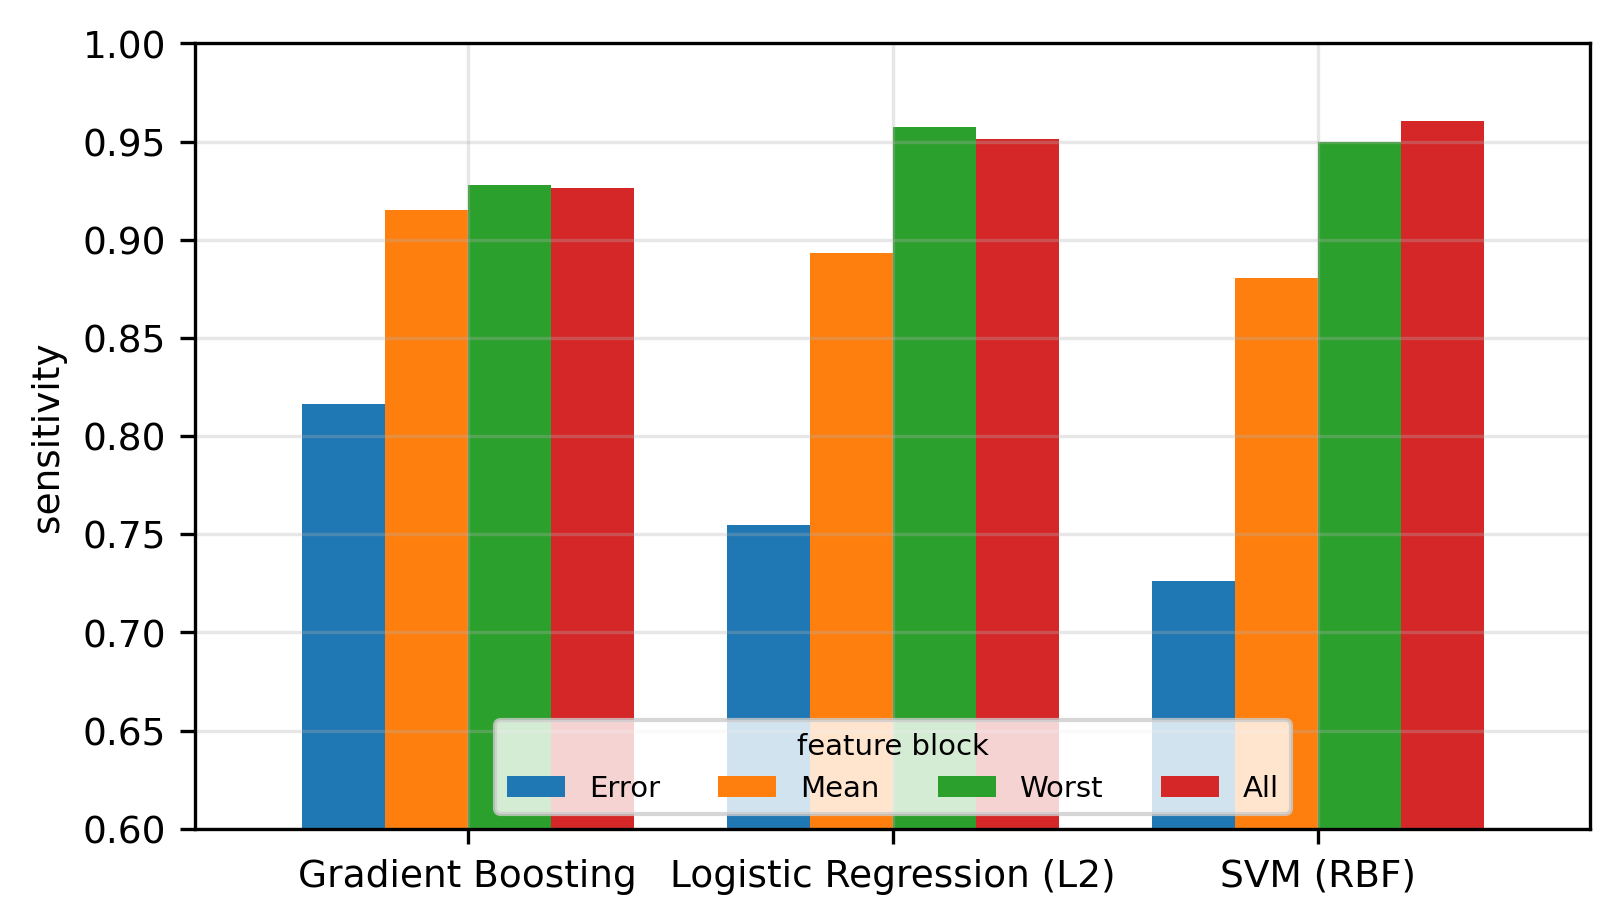

**fig_models**

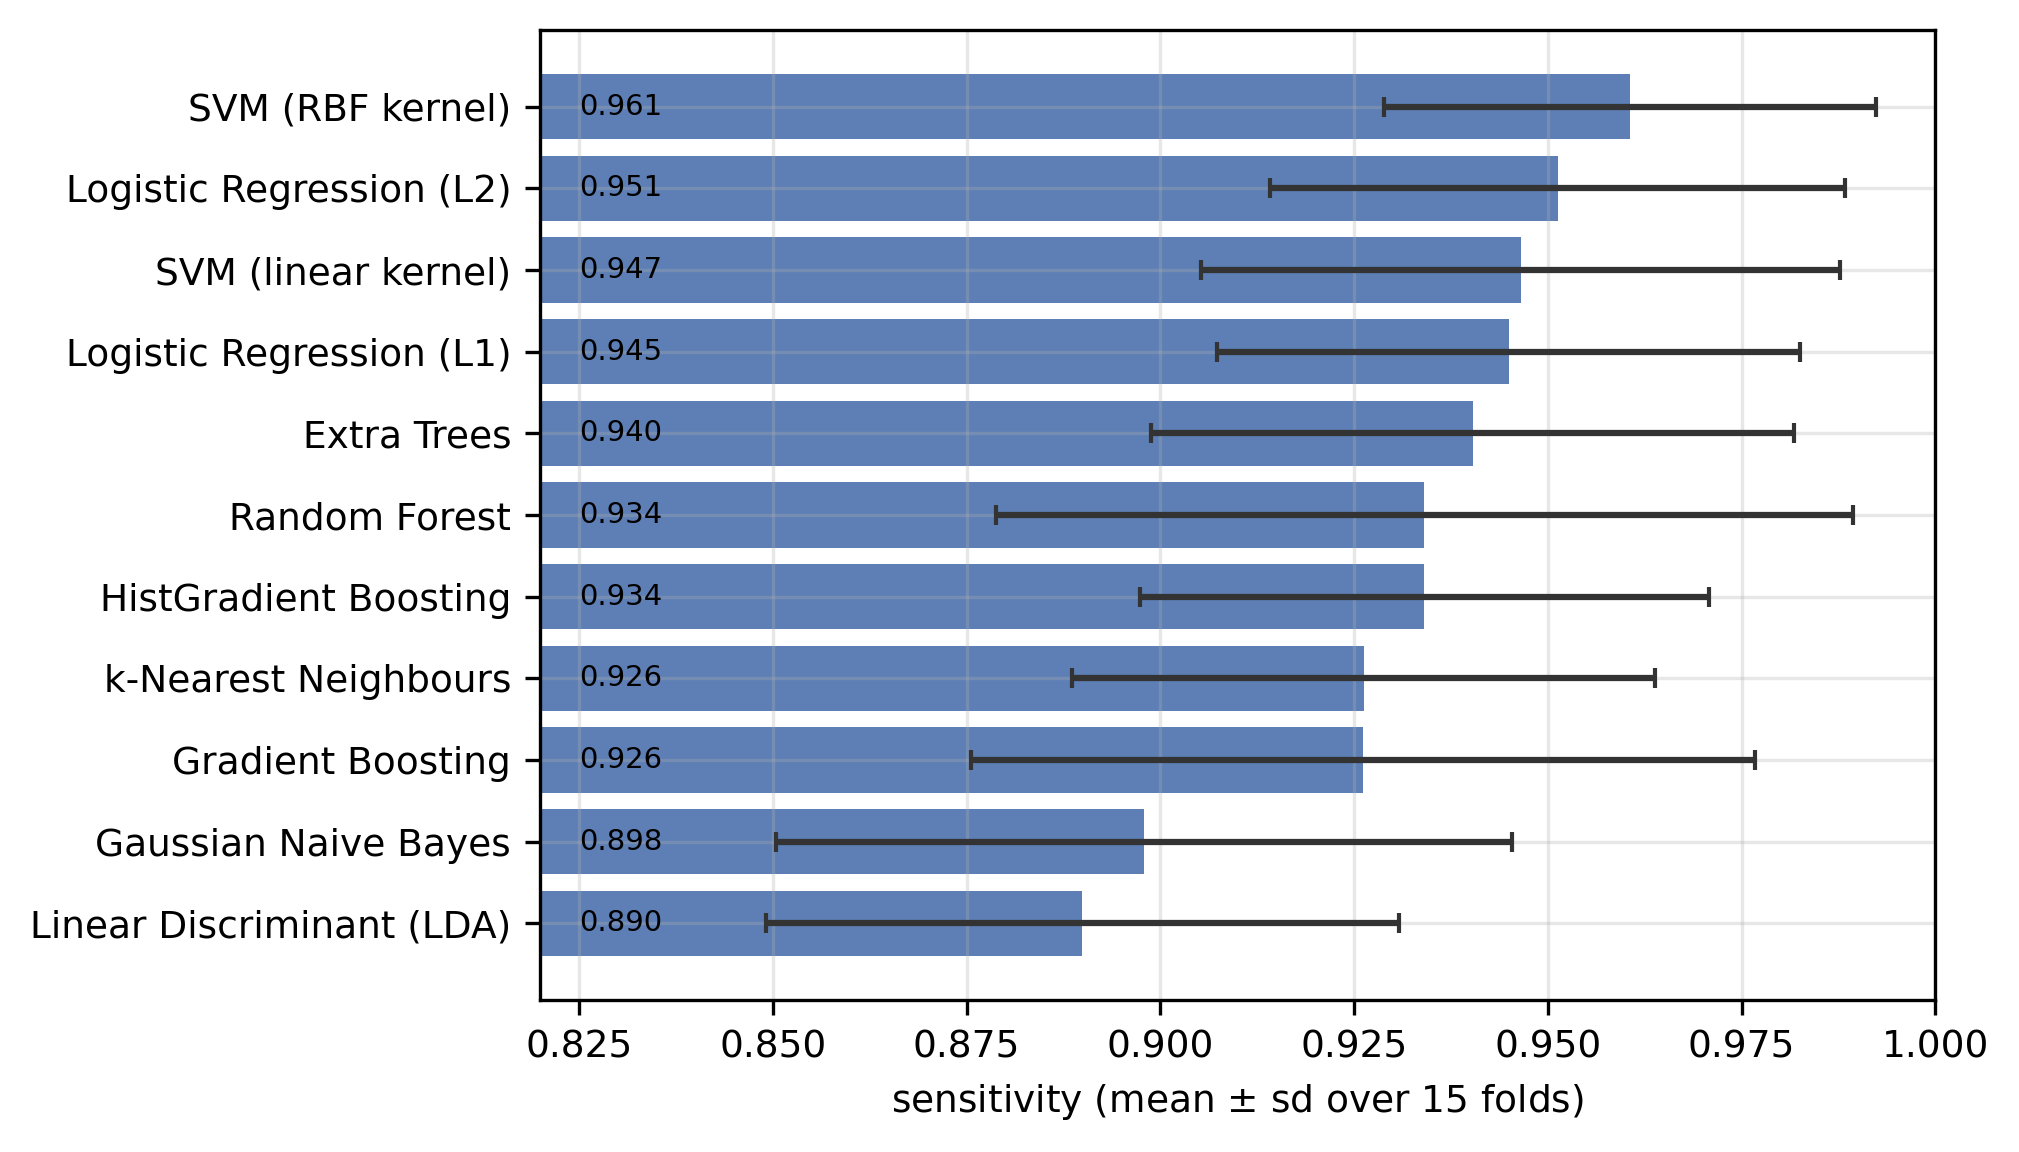

**fig_models2**

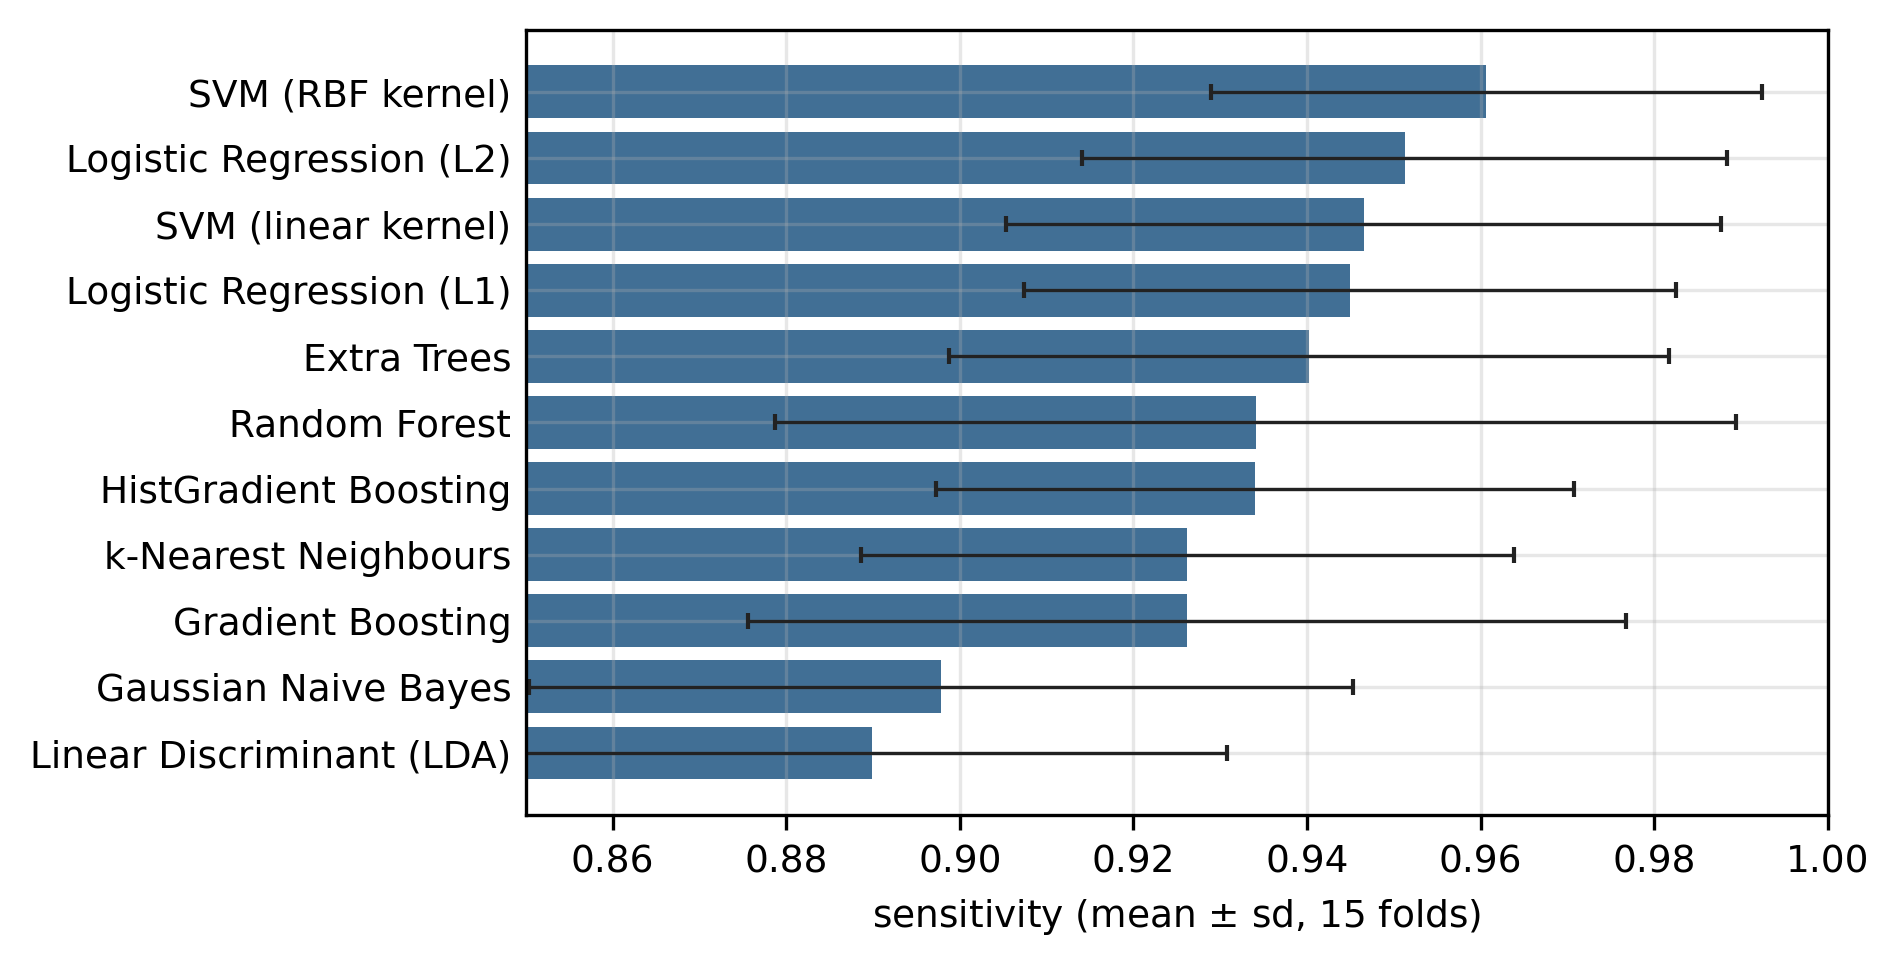

**fig_threshold**

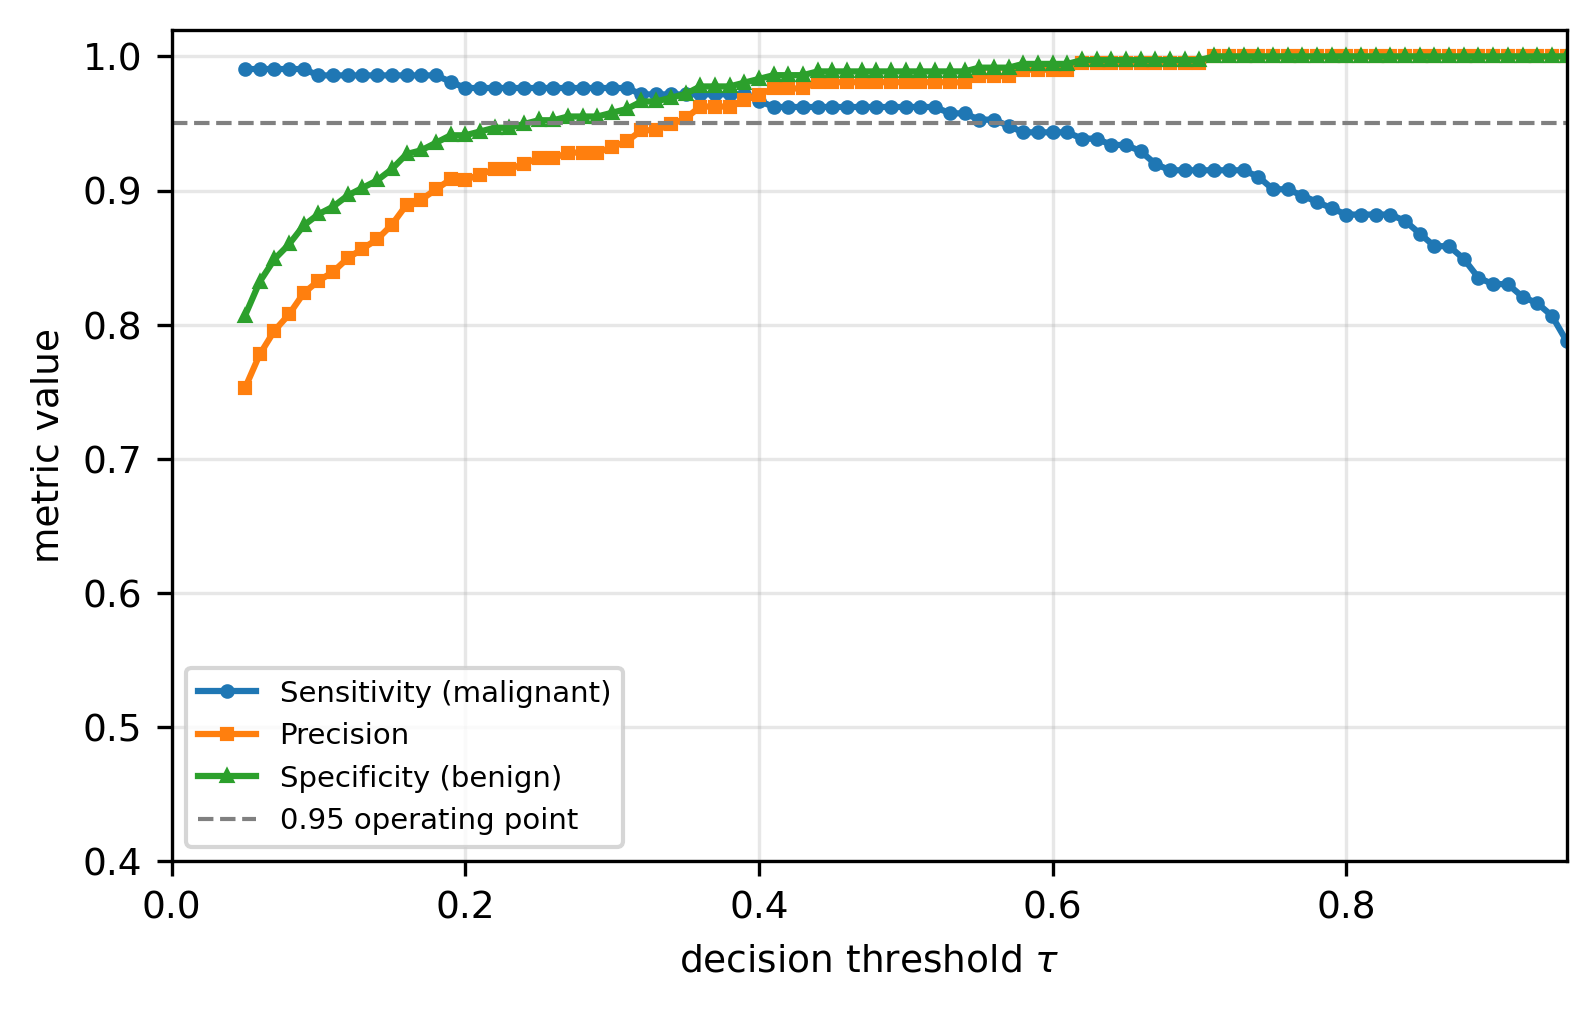

**fig_threshold2**

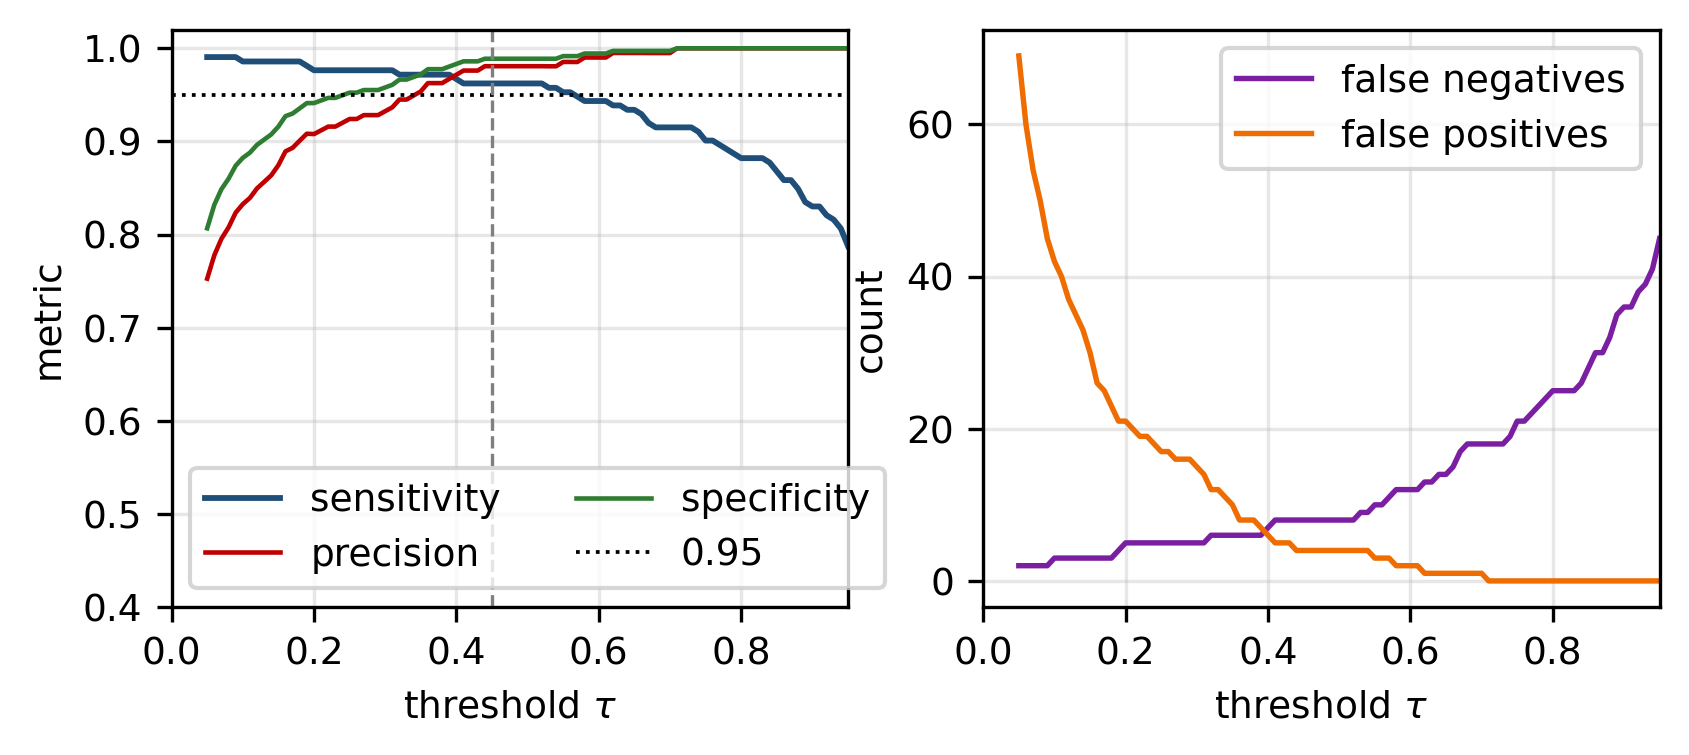

**fig_reliability**

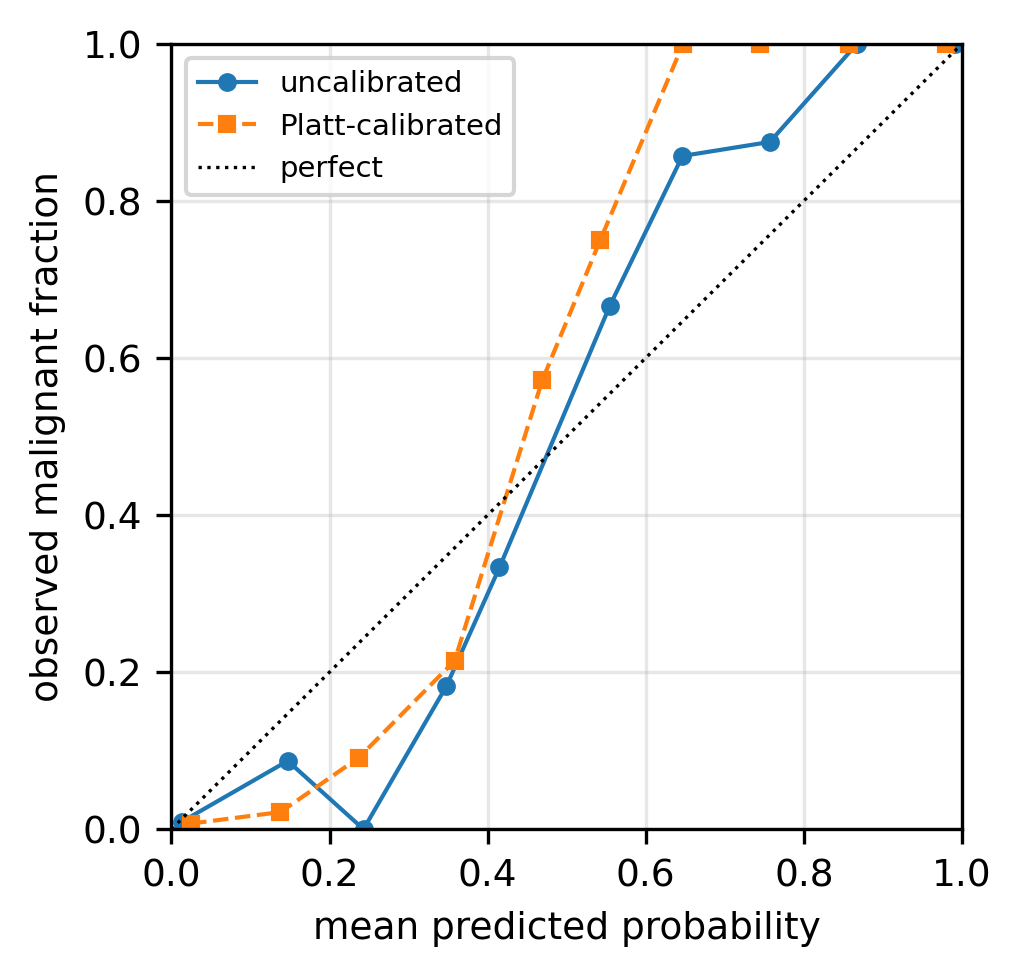

**fig_kernel**

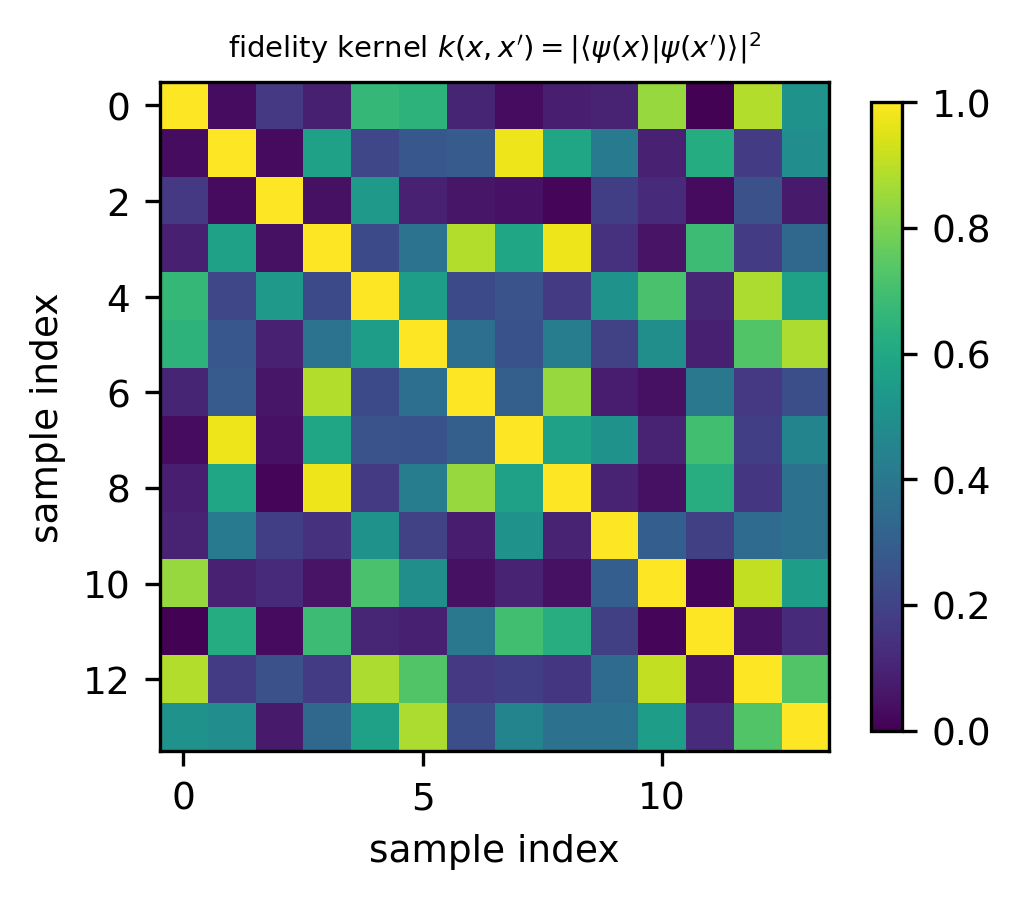

**fig_learning**

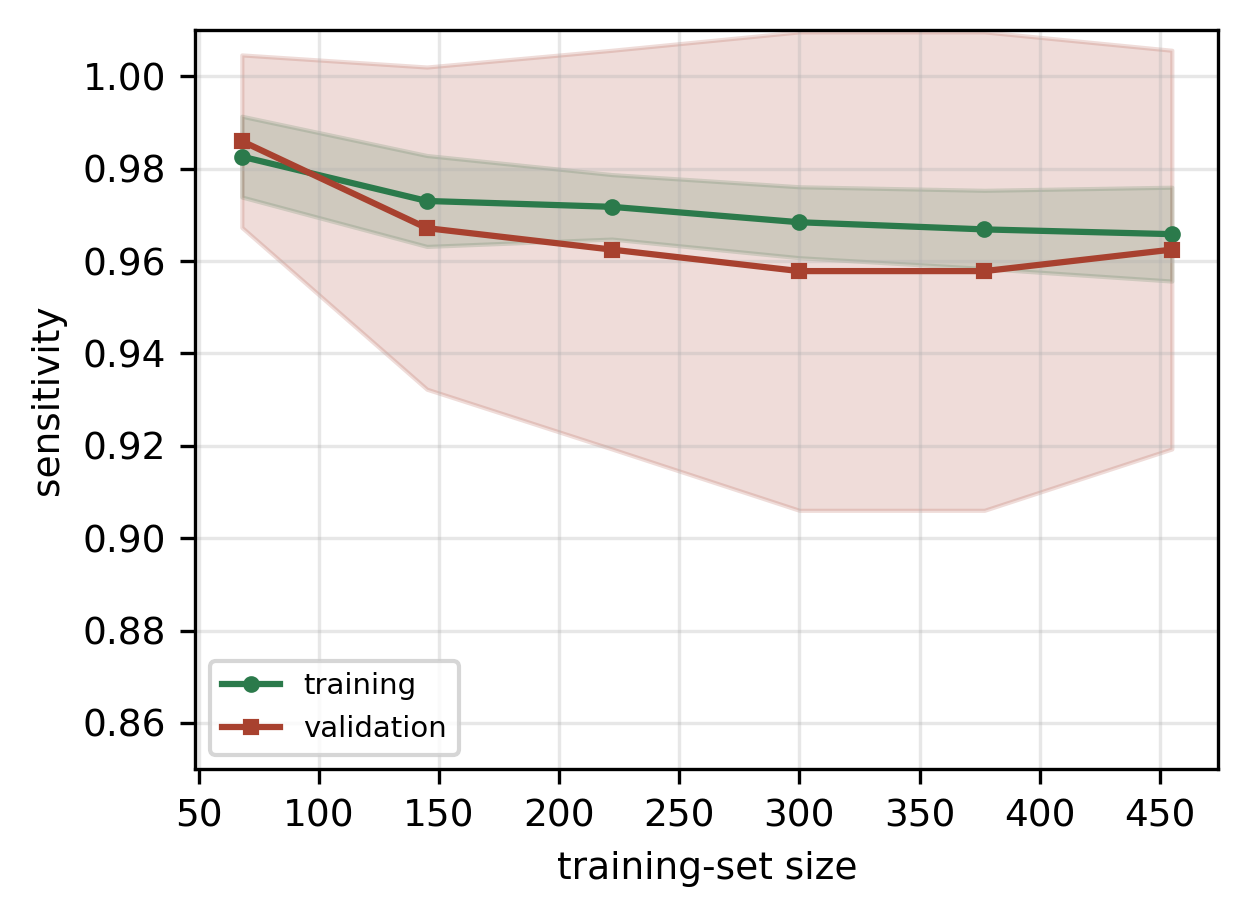

In [21]:
from IPython.display import Image, display, Markdown

EXPECTED_CSV = [
    "exp1_feature_blocks.csv", "exp2_model_zoo.csv", "exp2_architectures.csv",
    "exp3_feature_selection.csv", "exp4a_threshold_curve.csv",
    "exp4b_nested_threshold.csv", "exp5a_calibration.csv",
    "exp5b_reliability.csv", "exp5c_bootstrap_ci.csv",
    "exp6_quantum_vs_classical.csv", "exp7_mcnemar.csv",
    "exp7_bootstrap_diff.csv", "exp8_learning_curve.csv",
]
EXPECTED_FIG = ["fig_blocks", "fig_models", "fig_models2", "fig_threshold",
                "fig_threshold2", "fig_reliability", "fig_kernel", "fig_learning"]

missing = [c for c in EXPECTED_CSV if not (RES / c).exists()]
missing += [f + ".pdf" for f in EXPECTED_FIG if not (FIG / (f + ".pdf")).exists()]
assert not missing, f"MISSING ARTEFACTS: {missing}"

print(f"all {len(EXPECTED_CSV)} result files present")
print(f"all {len(EXPECTED_FIG)} figures present (PDF + PNG)")

for f in EXPECTED_FIG:
    display(Markdown(f"**{f}**"))
    display(Image(filename=str(FIG / f"{f}.png"), width=560))

In [22]:
print("=== results/ ===")
for p in sorted(RES.glob("*.csv")):
    print(f"  {p.name:34s} {p.stat().st_size:>7d} bytes")
print("\n=== figures/ ===")
for p in sorted(FIG.glob("*")):
    print(f"  {p.name:34s} {p.stat().st_size:>7d} bytes")

=== results/ ===
  exp1_feature_blocks.csv               2586 bytes
  exp2_architectures.csv                4448 bytes
  exp2_model_zoo.csv                    2835 bytes
  exp3_feature_selection.csv             553 bytes
  exp4a_threshold_curve.csv             9476 bytes
  exp4b_nested_threshold.csv             922 bytes
  exp5a_calibration.csv                  179 bytes
  exp5b_reliability.csv                 1206 bytes
  exp5c_bootstrap_ci.csv                 300 bytes
  exp6_quantum_vs_classical.csv          816 bytes
  exp7_bootstrap_diff.csv                137 bytes
  exp7_mcnemar.csv                       185 bytes
  exp8_learning_curve.csv                539 bytes

=== figures/ ===
  fig_blocks.pdf                       16244 bytes
  fig_blocks.png                       72177 bytes
  fig_kernel.pdf                       22112 bytes
  fig_kernel.png                       49696 bytes
  fig_learning.pdf                     13134 bytes
  fig_learning.png                    100164 by